# **Dulce Cristina Rodríguez Rodríguez**
## **Diplomado de programación en python para la web y análisis de datos**
### **Portafolio de evidencias de aprendizaje**
**Introducción:** El presente notebook desarrolla un análisis exploratorio de datos de resultados históricos de partidos internacionales de fútbol, con el objetivo de identificar patrones y características relevantes para clasificar los encuentros en amistosos y no amistosos, siguiendo las dos primeras fases de la metodología CRISP-DM.



#Notebook 1 - Análisis exploratorio de datos para un problema de clasificación


Metodología CRISP-DM: Fase 1 (Comprensión del negocio) y Fase 2 (Comprensión de los datos)

Dataset: resultados históricos de partidos internacionales de fútbol.

In [ ]:
# librerias y carga del dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cambia esta ruta si el archivo está guardado en otra ubicación.
RUTA_DATASET = "/content/results.csv"

df = pd.read_csv(RUTA_DATASET)

##FASE 1. Comprensión del negocio (Business understanding)


**1.1 Descripción del problema**:
El conjunto contiene resultados históricos de partidos internacionales
de fútbol. Se propone estudiar si un partido corresponde a un amistoso
o a otro tipo de torneo, a partir de la clasificación del torneo registrado.

**1.2 Importancia y contexto**:
Distinguir los partidos amistosos de los demás encuentros permite describir
cómo se distribuyen los resultados según el tipo de competición y explorar
si existen diferencias en los goles anotados. El análisis es descriptivo:
no permite concluir por sí solo que el tipo de partido cause un resultado.

**1.3 Objetivo general**:
Explorar los resultados históricos de partidos internacionales de fútbol
y describir la distribución de sus variables, con especial atención a la
clasificación entre partidos amistosos y no amistosos.

**1.4 Variable objetivo**:
Se construirá una etiqueta descriptiva llamada "tipo_partido":
- "Amistoso": cuando la columna tournament sea exactamente "Friendly".
- "No amistoso": para los demás valores de tournament.

**1.5 Utilidad potencial**:
Una futura solución de clasificación podría ayudar a categorizar partidos
cuando se disponga de información apropiada. Para entrenar un modelo sería
necesario definir qué variables estarían disponibles antes del partido y
evitar utilizar tournament como predictor si la etiqueta se deriva de él.


In [ ]:
print("FASE 1. COMPRENSIÓN DEL NEGOCIO")

#comprensión de los datos
print("\nPrimeras cinco filas:")
df.head()

FASE 1. COMPRENSIÓN DEL NEGOCIO

Primeras cinco filas:


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


In [ ]:
print("\nDimensiones:")
print(f"Registros: {df.shape[0]}")
print(f"Variables: {df.shape[1]}")

print("\nNombres de las variables:")
print(df.columns.tolist())

print("\nInformación y tipos de datos:")
df.info()


Dimensiones:
Registros: 41243
Variables: 9

Nombres de las variables:
['date', 'home_team', 'away_team', 'home_score', 'away_score', 'tournament', 'city', 'country', 'neutral']

Información y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41243 entries, 0 to 41242
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        41243 non-null  object
 1   home_team   41243 non-null  object
 2   away_team   41243 non-null  object
 3   home_score  41243 non-null  int64 
 4   away_score  41243 non-null  int64 
 5   tournament  41243 non-null  object
 6   city        41243 non-null  object
 7   country     41243 non-null  object
 8   neutral     41243 non-null  bool  
dtypes: bool(1), int64(2), object(6)
memory usage: 2.6+ MB


In [ ]:
#origen y significado de las variables
print("2.2 SIGNIFICADO DE LAS PRINCIPALES VARIABLES")
print("\n")
significado_variables = {
    "date": "Fecha en que se disputó el partido.",
    "home_team": "Equipo que figura como local.",
    "away_team": "Equipo que figura como visitante.",
    "home_score": "Goles anotados por el equipo local.",
    "away_score": "Goles anotados por el equipo visitante.",
    "tournament": "Torneo o tipo de competición registrado.",
    "city": "Ciudad donde se disputó el partido.",
    "country": "País o territorio indicado como sede.",
    "neutral": "Indica si el partido se jugó en una sede neutral."
}

for variable, significado in significado_variables.items():
    if variable in df.columns:
        print(f"{variable}: {significado}")

2.2 SIGNIFICADO DE LAS PRINCIPALES VARIABLES


date: Fecha en que se disputó el partido.
home_team: Equipo que figura como local.
away_team: Equipo que figura como visitante.
home_score: Goles anotados por el equipo local.
away_score: Goles anotados por el equipo visitante.
tournament: Torneo o tipo de competición registrado.
city: Ciudad donde se disputó el partido.
country: País o territorio indicado como sede.
neutral: Indica si el partido se jugó en una sede neutral.


In [ ]:
# 2.3 tipos de datos
print("2.3 TIPOS DE DATOS\n")
tipos_datos = pd.DataFrame({
    "Variable": df.columns,
    "Tipo_de_dato": [str(tipo) for tipo in df.dtypes],
    "Valores_no_nulos": df.notna().sum().values,
    "Valores_nulos": df.isna().sum().values
})

print(tipos_datos.to_string(index=False))

print(
    "\nInterpretación: object suele indicar texto; int64 representa "
    "enteros y bool representa valores lógicos. La fecha puede venir como "
    "texto al importar el CSV. Para el análisis de fechas se convertirá "
    "una copia de esa columna, sin eliminar registros."
)

# Crear una copia de la fecha como datetime únicamente para analizarla.
# No se eliminan filas si la fecha no puede interpretarse.
if "date" in df.columns:
    fecha_convertida = pd.to_datetime(df["date"], errors="coerce")
    print(
        "\nFechas que no pudieron interpretarse:",
        int(fecha_convertida.isna().sum() - df["date"].isna().sum())
    )


2.3 TIPOS DE DATOS

  Variable Tipo_de_dato  Valores_no_nulos  Valores_nulos
      date       object             41243              0
 home_team       object             41243              0
 away_team       object             41243              0
home_score        int64             41243              0
away_score        int64             41243              0
tournament       object             41243              0
      city       object             41243              0
   country       object             41243              0
   neutral         bool             41243              0

Interpretación: object suele indicar texto; int64 representa enteros y bool representa valores lógicos. La fecha puede venir como texto al importar el CSV. Para el análisis de fechas se convertirá una copia de esa columna, sin eliminar registros.

Fechas que no pudieron interpretarse: 0


In [ ]:
# 2.4 Valores faltantes y valores duplicados
print("2.4 VALORES FALTANTES Y REGISTROS DUPLICADOS")

faltantes = df.isna().sum().sort_values(ascending=False)
faltantes_porcentaje = (df.isna().mean() * 100).sort_values(ascending=False)

tabla_faltantes = pd.DataFrame({
    "Valores_faltantes": faltantes,
    "Porcentaje_faltante": faltantes_porcentaje.round(2)
})

print("\nValores faltantes por variable:")
print(tabla_faltantes.to_string())

duplicados = int(df.duplicated().sum())
print(f"\nRegistros completamente duplicados: {duplicados}")

print(
    "\nEn esta fase solo se identifican los valores faltantes y duplicados. "
    "No se eliminan filas ni se imputan valores, porque el alcance solicitado "
    "es el análisis exploratorio y las estadísticas descriptivas."
)

# Gráfica de valores faltantes (solo variables con al menos un faltante).
columnas_con_faltantes = faltantes[faltantes > 0]

if not columnas_con_faltantes.empty:
    plt.figure(figsize=(10, 5))
    columnas_con_faltantes.sort_values().plot(kind="barh")
    plt.title("Cantidad de valores faltantes por variable")
    plt.xlabel("Cantidad de valores faltantes")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.show()
else:
    print("No se detectaron valores faltantes.")

2.4 VALORES FALTANTES Y REGISTROS DUPLICADOS

Valores faltantes por variable:
            Valores_faltantes  Porcentaje_faltante
date                        0                  0.0
home_team                   0                  0.0
away_team                   0                  0.0
home_score                  0                  0.0
away_score                  0                  0.0
tournament                  0                  0.0
city                        0                  0.0
country                     0                  0.0
neutral                     0                  0.0

Registros completamente duplicados: 0

En esta fase solo se identifican los valores faltantes y duplicados. No se eliminan filas ni se imputan valores, porque el alcance solicitado es el análisis exploratorio y las estadísticas descriptivas.
No se detectaron valores faltantes.


In [ ]:
# 2.5 Estadísticas descriptivas variables numéricas
print("2.5 ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS\n")
numericas = df.select_dtypes(include=np.number)
numericas.describe()

2.5 ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS



,home_score,away_score
count,41243.000000,41243.000000
mean,1.744975,1.189317
std,1.750513,1.406648
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,31.000000,21.000000


In [ ]:
# 2.6 Estadistica descriptiva variables categoricas
print("2.6 ESTADÍSTICAS DESCRIPTIVAS CATEGÓRICAS\n")
categoricas = df.select_dtypes(include=["object", "category", "bool"])
categoricas.describe()

2.6 ESTADÍSTICAS DESCRIPTIVAS CATEGÓRICAS



,date,home_team,away_team,tournament,city,country,neutral
count,41243,41243,41243,41243,41243,41243,41243
unique,15154,310,307,112,2002,266,2
top,2012-02-29,Brazil,Uruguay,Friendly,Kuala Lumpur,United States,False
freq,66,567,539,17011,583,1154,31015


2.7 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO

Distribución de tipo_partido:
              Cantidad  Porcentaje
tipo_partido                      
No amistoso      24232       58.75
Amistoso         17011       41.25


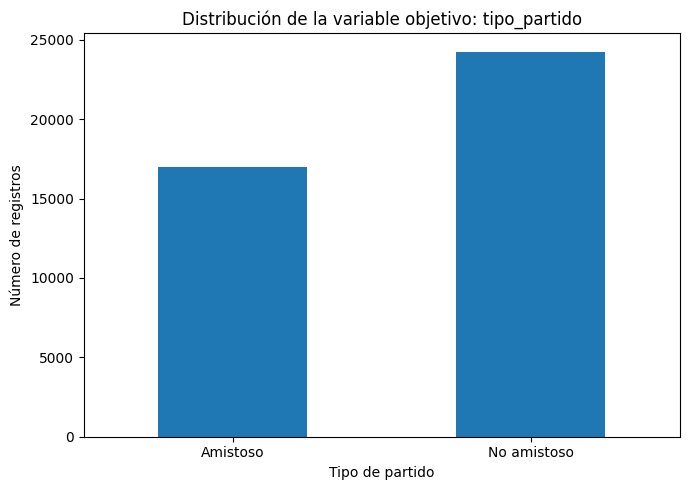

In [ ]:
# 2.7 Definir la variable objetivo
print("2.7 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")

if "tournament" not in df.columns:
    raise ValueError(
        "No se encontró la columna 'tournament'; revisa los nombres de columnas."
    )

# Esta variable solo etiqueta los registros para el análisis exploratorio.
# No se realiza modelado ni se utiliza esta etiqueta para entrenar un modelo.
torneo = df["tournament"].astype("string").str.strip()
df["tipo_partido"] = np.where(
    torneo.str.casefold().eq("friendly").fillna(False),
    "Amistoso",
    "No amistoso"
)

conteo_objetivo = df["tipo_partido"].value_counts()
porcentaje_objetivo = (
    df["tipo_partido"].value_counts(normalize=True) * 100
).round(2)

tabla_objetivo = pd.DataFrame({
    "Cantidad": conteo_objetivo,
    "Porcentaje": porcentaje_objetivo
})

print("\nDistribución de tipo_partido:")
print(tabla_objetivo.to_string())

plt.figure(figsize=(7, 5))
conteo_objetivo.reindex(["Amistoso", "No amistoso"]).dropna().plot(
    kind="bar"
)
plt.title("Distribución de la variable objetivo: tipo_partido")
plt.xlabel("Tipo de partido")
plt.ylabel("Número de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

2.8 GRÁFICAS EXPLORATORIAS


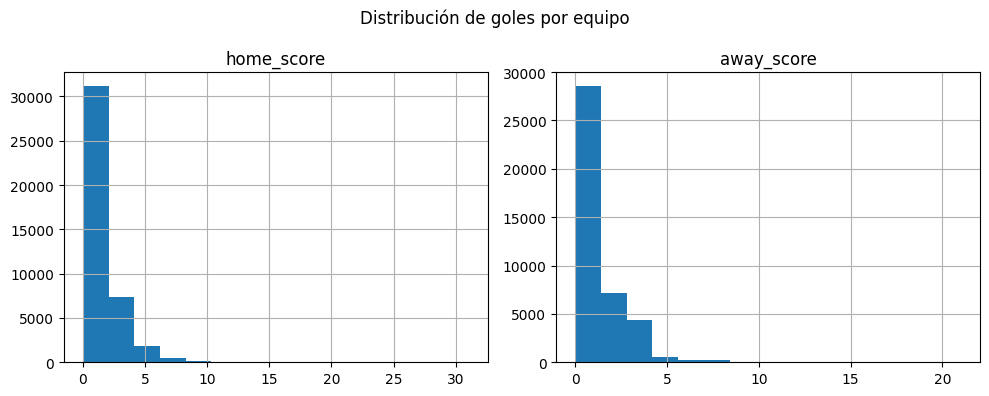

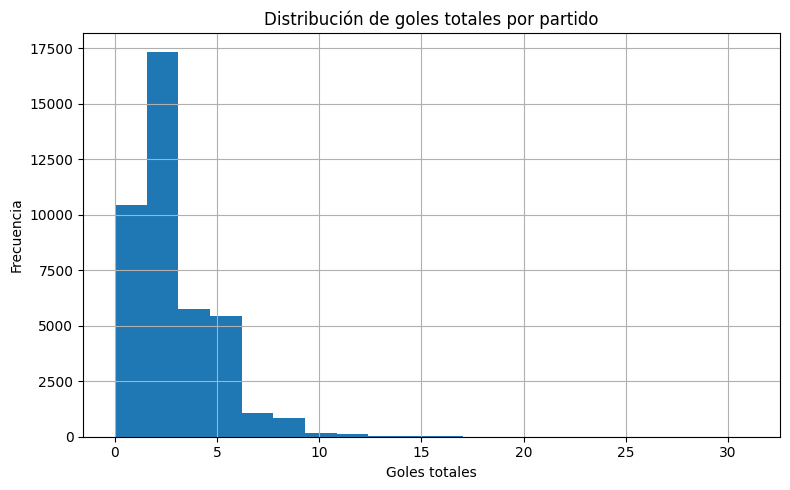

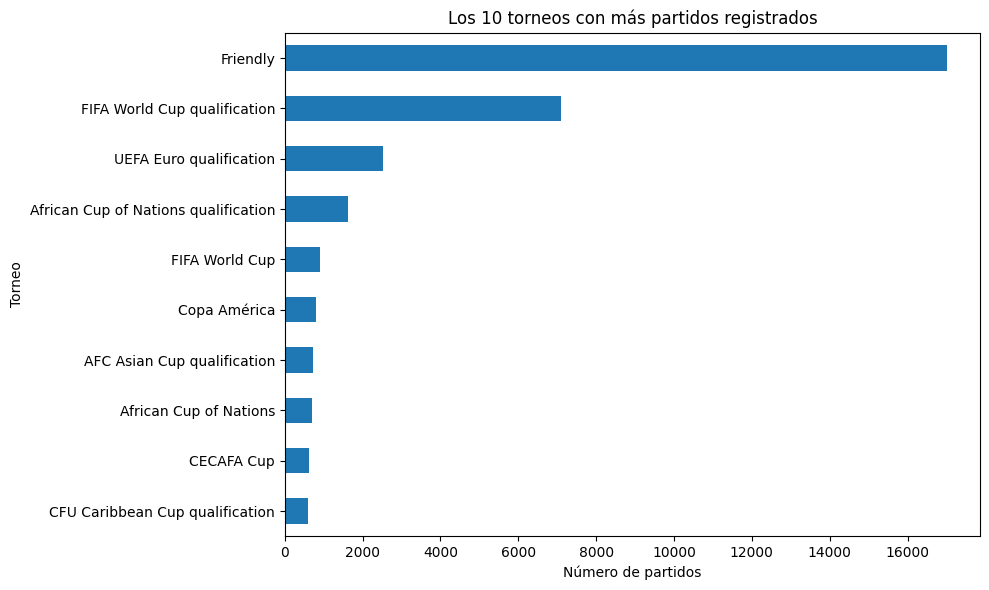

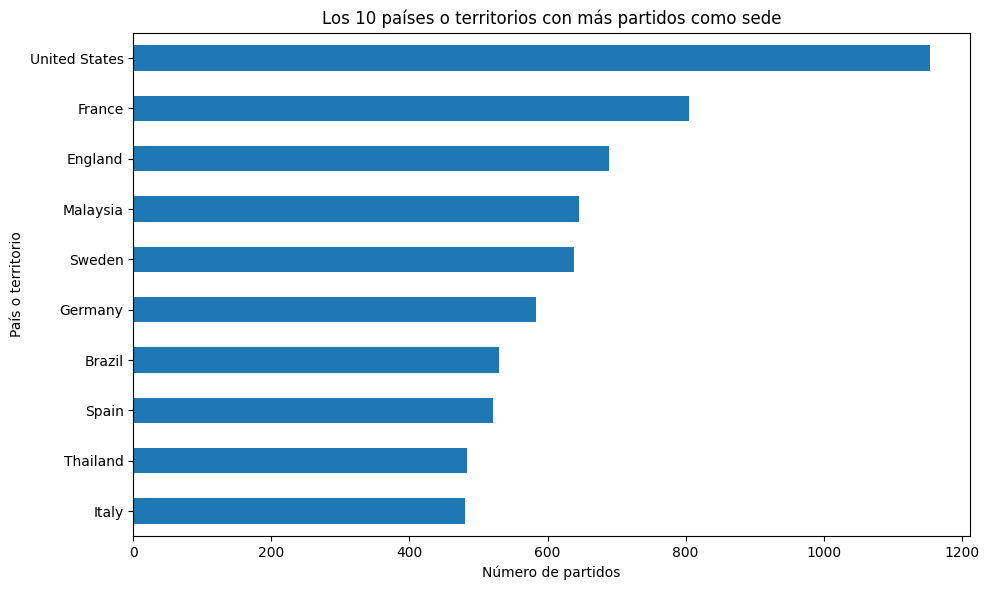

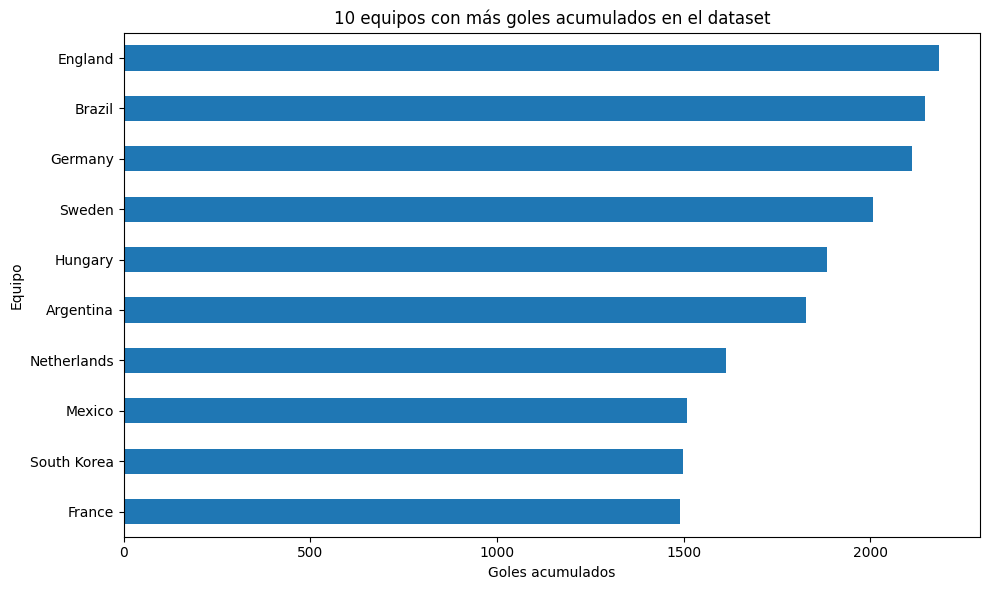


Promedio de goles por tipo de partido:
              count  mean  median   std
tipo_partido                           
Amistoso      17011  2.90     3.0  2.03
No amistoso   24232  2.96     3.0  2.14


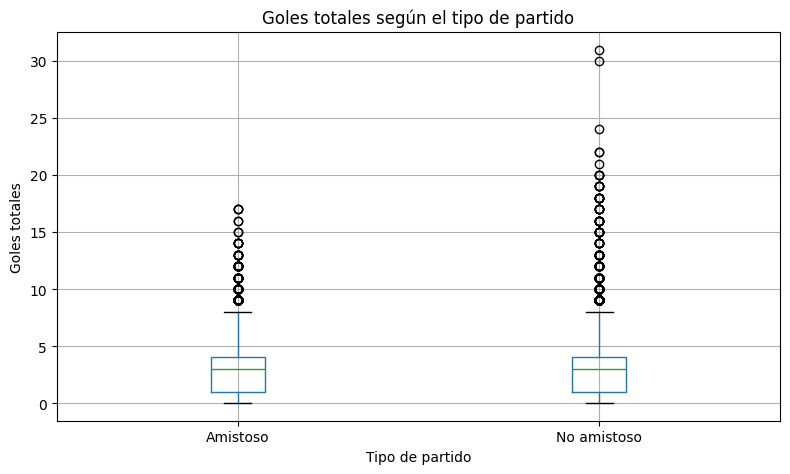

In [ ]:
#Gráficas
print("2.8 GRÁFICAS EXPLORATORIAS")
# A. Distribución de goles del equipo local y visitante.
columnas_goles = [
    columna for columna in ["home_score", "away_score"]
    if columna in df.columns
]

if columnas_goles:
    df[columnas_goles].hist(figsize=(10, 4), bins=15)
    plt.suptitle("Distribución de goles por equipo")
    plt.tight_layout()
    plt.show()

# B. Goles totales por partido.
if {"home_score", "away_score"}.issubset(df.columns):
    goles_local = pd.to_numeric(df["home_score"], errors="coerce")
    goles_visitante = pd.to_numeric(df["away_score"], errors="coerce")
    goles_totales = goles_local + goles_visitante

    plt.figure(figsize=(8, 5))
    goles_totales.dropna().hist(bins=20)
    plt.title("Distribución de goles totales por partido")
    plt.xlabel("Goles totales")
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

# C. Torneos con más registros.
if "tournament" in df.columns:
    top_torneos = df["tournament"].value_counts().head(10)

    plt.figure(figsize=(10, 6))
    top_torneos.sort_values().plot(kind="barh")
    plt.title("Los 10 torneos con más partidos registrados")
    plt.xlabel("Número de partidos")
    plt.ylabel("Torneo")
    plt.tight_layout()
    plt.show()

# D. Países con más partidos registrados.
if "country" in df.columns:
    top_paises = df["country"].value_counts().head(10)

    plt.figure(figsize=(10, 6))
    top_paises.sort_values().plot(kind="barh")
    plt.title("Los 10 países o territorios con más partidos como sede")
    plt.xlabel("Número de partidos")
    plt.ylabel("País o territorio")
    plt.tight_layout()
    plt.show()

# E. Equipos con más goles registrados, sumando sus goles como local
# y como visitante. Es un conteo descriptivo, no una medida de calidad.
columnas_requeridas = {"home_team", "away_team", "home_score", "away_score"}

if columnas_requeridas.issubset(df.columns):
    goles_local_df = df[["home_team", "home_score"]].copy()
    goles_local_df.columns = ["equipo", "goles"]
    goles_visitante_df = df[["away_team", "away_score"]].copy()
    goles_visitante_df.columns = ["equipo", "goles"]

    goles_local_df["goles"] = pd.to_numeric(
        goles_local_df["goles"], errors="coerce"
    )
    goles_visitante_df["goles"] = pd.to_numeric(
        goles_visitante_df["goles"], errors="coerce"
    )

    goles_equipos = pd.concat(
        [goles_local_df, goles_visitante_df],
        ignore_index=True
    )

    top_goleadores = (
        goles_equipos.groupby("equipo")["goles"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    plt.figure(figsize=(10, 6))
    top_goleadores.sort_values().plot(kind="barh")
    plt.title("10 equipos con más goles acumulados en el dataset")
    plt.xlabel("Goles acumulados")
    plt.ylabel("Equipo")
    plt.tight_layout()
    plt.show()

# F. Goles promedio por tipo de partido.
if {"home_score", "away_score"}.issubset(df.columns):
    resumen_goles = pd.DataFrame({
        "tipo_partido": df["tipo_partido"],
        "goles_totales": goles_totales
    })

    print("\nPromedio de goles por tipo de partido:")
    print(
        resumen_goles.groupby("tipo_partido")["goles_totales"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
        .to_string()
    )

    resumen_goles.boxplot(
        column="goles_totales",
        by="tipo_partido",
        figsize=(8, 5)
    )
    plt.title("Goles totales según el tipo de partido")
    plt.suptitle("")
    plt.xlabel("Tipo de partido")
    plt.ylabel("Goles totales")
    plt.tight_layout()
    plt.show()

In [ ]:
# 2.9 Interpretación de los hallazgos encontrados
print("2.9 INTERPRETACIÓN DE LOS PRINCIPALES HALLAZGOS\n")

print(f"El dataset contiene {df.shape[0]} registros y {df.shape[1] - 1} "
      "variables originales, más la etiqueta exploratoria tipo_partido.\n")

print(f"Se encontraron {duplicados} registros completamente duplicados.\n")

total_faltantes = int(df.drop(columns=["tipo_partido"]).isna().sum().sum())
print(f"Se identificaron {total_faltantes} celdas vacías en las variables "
      "originales.\n")

if len(conteo_objetivo) > 0:
    clase_mayoritaria = conteo_objetivo.idxmax()
    cantidad_mayoritaria = int(conteo_objetivo.max())
    porcentaje_mayoritario = cantidad_mayoritaria / len(df) * 100
    print(
        f"La clase más frecuente es '{clase_mayoritaria}', con "
        f"{cantidad_mayoritaria} partidos ({porcentaje_mayoritario:.2f}%).\n"
    )

if {"home_score", "away_score"}.issubset(df.columns):
    print(
        f"El promedio de goles totales por partido es "
        f"{goles_totales.mean():.2f}.\n"
    )
    print(
        f"El máximo de goles totales registrado en una fila es "
        f"{goles_totales.max():.0f}.\n"
    )


2.9 INTERPRETACIÓN DE LOS PRINCIPALES HALLAZGOS

El dataset contiene 41243 registros y 9 variables originales, más la etiqueta exploratoria tipo_partido.

Se encontraron 0 registros completamente duplicados.

Se identificaron 0 celdas vacías en las variables originales.

La clase más frecuente es 'No amistoso', con 24232 partidos (58.75%).

El promedio de goles totales por partido es 2.93.

El máximo de goles totales registrado en una fila es 31.



## Conclusión


El análisis permitió conocer la estructura y distribución de los datos, identificar valores faltantes, duplicados y patrones en los resultados de los partidos. Estos hallazgos establecen una base para las siguientes etapas del proyecto de clasificación.